# RV of a spot and a facula transit: gaussian fit vs template matching (Bouchy et al. 2001)

The CCFs of a spot transit and of a facula transit (MURaM spectra, same setup as the tutorial) are measured in two ways:

1. **gaussian fit**: SunSim now (`compute_ccf_params`), the mean of a gaussian + offset fitted to the CCF.
2. **template matching** (Bouchy, Pepe & Queloz 2001): the CCF C is compared pixel by pixel with a template T, the disc-integrated CCF of the quiet star. For a small shift, C(v) = T(v − RV) ≈ T(v) − RV T′(v), so
   1. the derivative of the template, T′ = dT/dv;
   2. every pixel i of the window gives a shift $v_i = -(C_i - T_i)\,/\,T'_i$;
   3. the RV is the mean of the $v_i$ weighted by $W_i = T_i'^2$:
   $$\mathrm{RV} = \frac{\sum_i W_i\, v_i}{\sum_i W_i} = -\frac{\sum_i (C_i - T_i)\, T'_i}{\sum_i T_i'^2}.$$

Both RVs are relative to the quiet star (0 for the quiet star).

Notes on the template method:
- **Weights.** The sum is divided by Σ W_i, not by the number of pixels N. Σ W_i v_i / N is RV × mean(W): it is in m/s × (dC/dv)², not m/s. With photon noise, W_i = T′_i² / σ_i² (Bouchy eq. 8). The CCFs here are noise-free, so σ_i is constant.
- **No division by T′.** At the peak and in the continuum T′ ≈ 0: v_i diverges but its weight is 0. The second form of the formula has no division by T′, so it is used.
- **Normalisation.** A dark spot lowers the flux of the star and so the amplitude of the CCF, and a factor a on C would change the RV into a × RV. Before the comparison, every CCF is scaled to the area of the template (C → C ΣT / ΣC), which a pure shift does not change.
- **Window.** The same as the gaussian fit: the points between the wings of the first CCF (`speed_bisector_nb`, as in `compute_ccf_params`).

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import time as timer
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

from sunsim import *
from sunsim import local_path, nbspectra

## 1. Star, spectra and CCF grids

As in sections 2.4 and 7 of the tutorial:
- **Spectra**: MURaM high resolution spectra of the quiet photosphere and of the faculae (200 G). The spot spectrum is the quiet one (vx-drift corrected SSD) times the black-body ratio for ΔT = 500 K.
- **CCF setup**: HARPS G2 mask, 30 rings. The Dumusque bisector is added to the spot only.
- **Time series**: one rotation with 121 epochs. The regions are on the equator at longitude 180°: they cross the centre of the disc at t = P/2, and none is visible at t = 0.

In [2]:
rotation_period = 24.47            # [days]
inclination = 0                    # [rad] equator-on
T_quiet = 5770                     # [K]
spot_dT = 700                      # [K]
N_rings = 100
time = np.linspace(0, rotation_period, 121)

flux_quiet = np.load(str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_fc = np.load(str(local_path('muram_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_sp = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
for mu in flux_sp:
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], T_quiet - spot_dT) / black_body(flux_sp[mu]['wav'], T_quiet)

wvm, fm = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]

def make_ccf_grid(flux, cb, bisector):
    g = CCF_grid(N_rings, flux, rv_grid, wvm, fm, convective_blueshift=cb, phoenix_resolution=True, normalization=False)
    g.built_grid(bisector=bisector)
    return g

ccf_quiet = make_ccf_grid(flux_quiet, 0, None)
ccf_fac = make_ccf_grid(flux_fc, 0, None)
ccf_spot = make_ccf_grid(flux_sp, 1, dumusque_bisector(normalization=False))

## 2. Simulations, template and window

`quiet` has no region: its CCF is the template (the same at every epoch). The first epoch of `spot` and `facula` is also the quiet star (checked).

In [3]:
scenarios = {
    'quiet':  [],
    'spot':   [active_region('sp', 10, 90, 180)],
    'facula': [active_region('fc', 10, 90, 180)],
}
sims = {}
for name, regions in scenarios.items():
    ss = StarSim(time, N_rings, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=SOLAR_DIFFERENTIAL_ROTATION, active_regions_map=regions, mode=['ccf'],
                 stellar_radius=1, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
    ss.generate_timeseries(verbose=False)
    sims[name] = ss

rv = sims['quiet'].ccf_rv
template = sims['quiet'].ccf_var[0]
for name in ('spot', 'facula'):
    assert np.allclose(sims[name].ccf_var[0], template, rtol=1e-12, atol=0), name

# window of the gaussian fit (compute_ccf_params): between the wings of the first CCF
c0 = template - template.min() + 0.000001
cutleft, cutright, _, _ = nbspectra.speed_bisector_nb(np.ascontiguousarray(rv, dtype=np.float64), c0 / c0.max(), True)
window = np.zeros(len(rv), dtype=bool)
window[int(cutleft):int(cutright)] = True
print('template: RV = %.1f m/s, FWHM = %.1f m/s (gaussian fit), vsini = %.0f m/s'
      % (sims['quiet'].rv_var[0], sims['quiet'].fwhm_var[0], sims['quiet'].vsini))
print('window: %.2f to %.2f km/s (%d points)' % (rv[window][0] / 1e3, rv[window][-1] / 1e3, window.sum()))

template: RV = -968.2 m/s, FWHM = 6989.8 m/s (gaussian fit), vsini = 2069 m/s
window: -10.50 to 8.95 km/s (779 points)


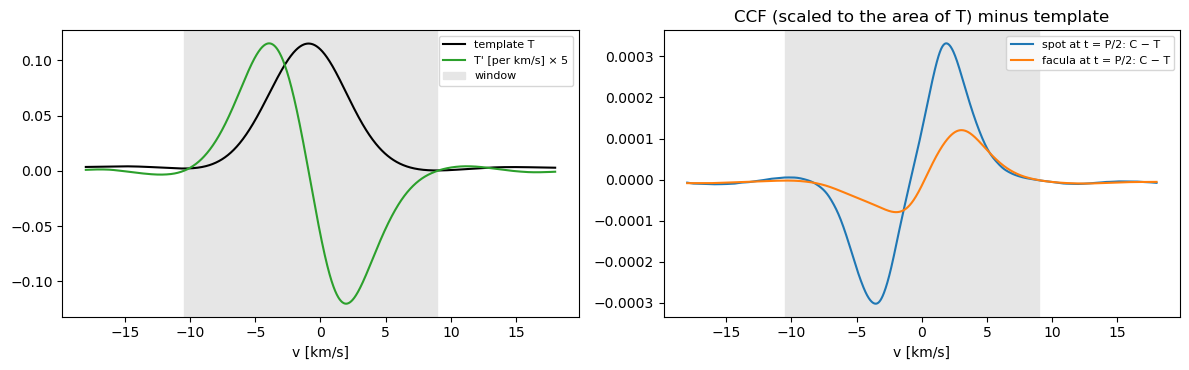

In [4]:
# SunSim CCFs are peaks (the inverted line). Left: template, its derivative and the window. Right: CCF minus template
# at the centre of the transit, and the shift alone (-RV T') that template matching fits to it.
dT = CubicSpline(rv, template)(rv, 1)
k_c = np.argmin(np.abs(time - rotation_period / 2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(rv / 1e3, template, 'k', label='template T')
ax[0].plot(rv / 1e3, dT * 1e3 * 5, 'C2', label="T' [per km/s] × 5")
ax[0].axvspan(rv[window][0] / 1e3, rv[window][-1] / 1e3, color='0.9', zorder=0, label='window')
ax[0].set_xlabel('v [km/s]'); ax[0].legend(fontsize=8)
for j, name in enumerate(('spot', 'facula')):
    c = sims[name].ccf_var[k_c]
    c = c * template.sum() / c.sum()
    ax[1].plot(rv / 1e3, c - template, 'C%d' % j, label='%s at t = P/2: C − T' % name)
ax[1].axvspan(rv[window][0] / 1e3, rv[window][-1] / 1e3, color='0.9', zorder=0)
ax[1].set_xlabel('v [km/s]'); ax[1].set_title('CCF (scaled to the area of T) minus template'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Template matching

In [5]:
def template_rv(rv, ccfs, template, window):
    """RV of every CCF (rows of ccfs) relative to the template (Bouchy et al. 2001), on the points of window:
    every CCF is scaled to the area of the template, then v_i = -(C_i - T_i) / T'_i for every point i and
    RV = sum(W_i v_i) / sum(W_i) with W_i = T'_i^2, computed as -sum((C_i - T_i) T'_i) / sum(T'_i^2)."""
    ccfs = np.atleast_2d(ccfs)
    ccfs = ccfs * (template.sum() / ccfs.sum(axis=1))[:, None]
    dT = CubicSpline(rv, template)(rv, 1)[window]       # 1. dT/dv
    diff = ccfs[:, window] - template[window]            # 2. C_i - T_i (v_i = -diff / dT)
    W = dT**2                                            # 3. weights
    return -np.sum(diff * dT, axis=1) / np.sum(W)

### Check: the template shifted by known RVs

The template is shifted by RV and its amplitude multiplied by 0.98, which the area normalisation must remove. The method is linear in the shift (first order Taylor expansion), so it loses accuracy when the shift is no longer small compared with the width of the CCF (≈ 7 km/s).

In [6]:
spl = CubicSpline(rv, template)
shifts = np.array([1, 5, 20, -50, 100, 300])                    # [m/s]
fake = np.array([0.98 * spl(rv - s) for s in shifts])
rv_t = template_rv(rv, fake, template, window)
for s, r in zip(shifts, rv_t):
    print('injected %5.0f m/s -> template matching %9.4f m/s (error %+.4f m/s)' % (s, r, r - s))

injected     1 m/s -> template matching    1.0000 m/s (error -0.0000 m/s)
injected     5 m/s -> template matching    5.0000 m/s (error -0.0000 m/s)
injected    20 m/s -> template matching   19.9995 m/s (error -0.0005 m/s)
injected   -50 m/s -> template matching  -49.9983 m/s (error +0.0017 m/s)
injected   100 m/s -> template matching   99.9640 m/s (error -0.0360 m/s)
injected   300 m/s -> template matching  299.1672 m/s (error -0.8328 m/s)


## 4. Spot and facula transits

The gaussian RV is relative to the first epoch (the quiet star), the template RV is relative to the template (also the quiet star). Time from the crossing of the disc centre.

In [7]:
res = {}
for name in ('spot', 'facula'):
    ss = sims[name]
    t0 = timer.perf_counter(); rv_g, *_ = ss.compute_ccf_params(); tG = timer.perf_counter() - t0
    t0 = timer.perf_counter(); rv_t = template_rv(rv, ss.ccf_var, template, window); tT = timer.perf_counter() - t0
    res[name] = dict(gauss=rv_g - rv_g[0], template=rv_t)
    print('%-7s %d CCFs: gaussian fit + bisector %.4f s, template matching %.4f s' % (name, len(ss.ccf_var), tG, tT))

spot    121 CCFs: gaussian fit + bisector 0.0047 s, template matching 0.0006 s
facula  121 CCFs: gaussian fit + bisector 0.0042 s, template matching 0.0005 s


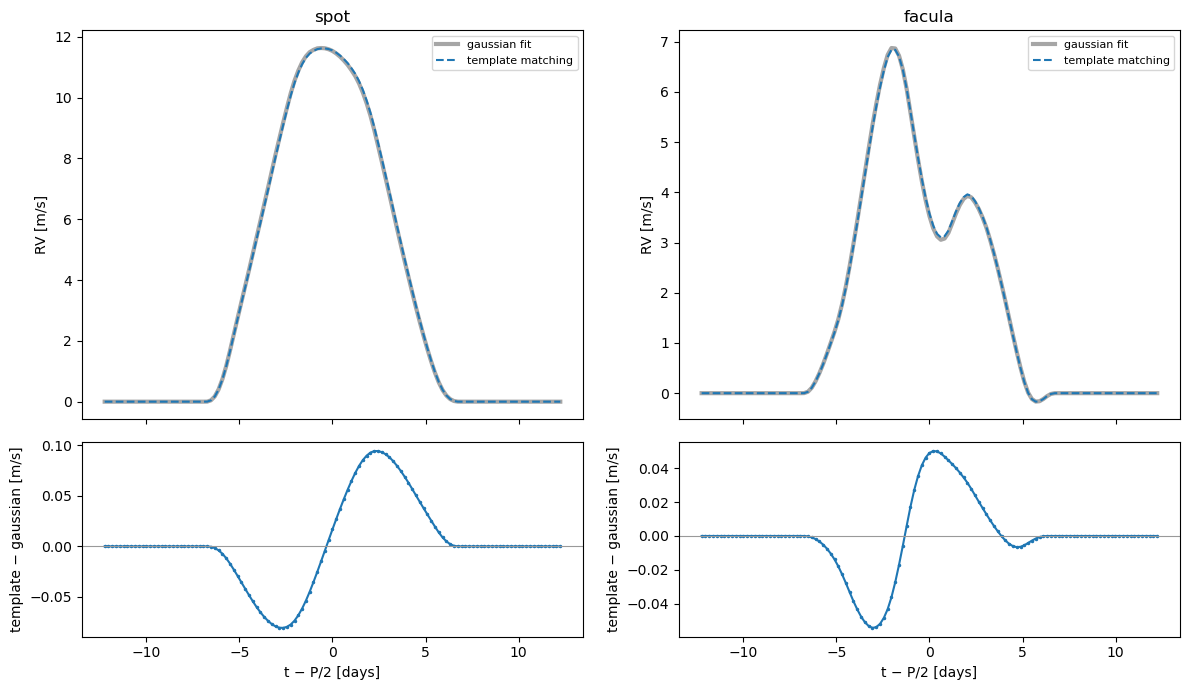

In [8]:
th = time - rotation_period / 2
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, name in enumerate(('spot', 'facula')):
    r = res[name]
    ax = axes[0, j]
    ax.plot(th, r['gauss'], 'k-', lw=3, alpha=0.35, label='gaussian fit')
    ax.plot(th, r['template'], 'C0--', label='template matching')
    ax.set_ylabel('RV [m/s]'); ax.set_title(name); ax.legend(fontsize=8)
    ax = axes[1, j]
    ax.plot(th, r['template'] - r['gauss'], 'C0.-', ms=3)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_ylabel('template − gaussian [m/s]'); ax.set_xlabel('t − P/2 [days]')
plt.tight_layout(); plt.show()

In [9]:
for name in ('spot', 'facula'):
    g, t = res[name]['gauss'], res[name]['template']
    d = t - g
    print('%-7s peak to peak: gaussian %.3f m/s, template %.3f m/s | template - gaussian: rms %.3f m/s, max |diff| %.3f m/s'
          % (name, np.ptp(g), np.ptp(t), np.std(d), np.max(np.abs(d))))

spot    peak to peak: gaussian 11.631 m/s, template 11.619 m/s | template - gaussian: rms 0.042 m/s, max |diff| 0.094 m/s
facula  peak to peak: gaussian 7.041 m/s, template 7.006 m/s | template - gaussian: rms 0.022 m/s, max |diff| 0.054 m/s


## 5. Summary

Noise-free simulations; the template comes from the same grids as the CCFs. Numbers from the outputs above.

**Check.** Shifts up to 50 m/s are recovered to better than 0.002 m/s. The amplitude factor of 0.98 is removed by the area normalisation (without it the RVs would be 2 % too small). The method is first order in the shift: the error is 0.04 m/s at 100 m/s and 0.8 m/s at 300 m/s. For large shifts the template would have to be shifted by the RV found and the comparison redone.

**Transits.** Template matching gives the same RV as the gaussian fit:

| region | peak to peak | rms difference | maximum difference |
|---|---|---|---|
| spot | 11.7 m/s | 0.042 m/s | 0.09 m/s (< 1 %) |
| facula | 7.0 m/s | 0.022 m/s | 0.05 m/s (< 1 %) |

The difference is antisymmetric around the crossing of the disc centre: negative at ingress, positive at egress. The two methods weight the asymmetric part of the change of the CCF differently. The gaussian fit weights it by the derivative of a gaussian, template matching by the derivative of the real CCF. For these nearly gaussian solar CCFs, the template brings no significant change in RV.

**Cost.** 0.5 ms for 121 CCFs, against 2.5 ms for the gaussian fit + bisector.

**Not tested here:** photon noise (weights T′²/σ², for which Bouchy et al. give the RV uncertainty), and CCFs far from a gaussian (M dwarfs, fast rotators), where the two RVs could differ more.

## 6. Contrast, FWHM and BIS with the template

The same idea as section 3: every indicator is a linear function of C − T, computed once from the template and applied to all the epochs with one matrix product. First order in the change of the CCF.

**Contrast, RV and FWHM: joint least squares** on the window (the generalisation of Bouchy, whose only basis function is T′):
$$C - T \approx b + a\,T - \mathrm{RV}\,T' - s\,(v - v_0)\,T'$$
- $b + a\,T$: offset and scale. `compute_ccf_params` fits the amplitude of C − min(C), so the offset cancels and the amplitude is multiplied by 1 + a: **Δcontrast = a × contrast(T)**. This term replaces the area normalisation of section 3 (the area normalisation would remove the contrast change).
- $-s\,(v - v_0)\,T'$: a stretch of the profile around its centre $v_0$, $T(v_0 + (v - v_0)/(1 + s)) \approx T - s\,(v - v_0)\,T'$: **ΔFWHM = s × FWHM(T)**, what a gaussian fit sees for a stretch. T and $(v - v_0)T'$ are both even, so a and s must be fitted together; T′ is odd and nearly orthogonal to them. $v_0$ = centre of the gaussian fit of T, so that RV is a shift of the centre.
- **Scale.** For C = (1 + a) T(v − RV) + b the coefficient of −T′ is (1 + a) RV, not RV: RV, s and the flank shifts below are divided by 1 + a (the derivative of the scaled template). Without it, a contrast change of −10 % gives a RV 10 % too small.

**BIS: Bouchy's $v_i$ averaged over the bisector bands.** $v_i = -(C_i - T_i)/T'_i$ is how far the flank moves at the height of pixel i. `compute_ccf_params` takes the heights relative to the minimum and the maximum of the CCF, $y = (C - C_\min)/(C_\max - C_\min)$, so at a fixed y the change of the CCF is corrected for the change of its minimum and maximum:
$$D_i = \Delta C_i - \Delta C_{\min} - y_i\,(\Delta C_{\max} - \Delta C_{\min}), \qquad \delta v_i = -D_i / T'_i$$
($D = 0$ for a pure scale and offset, as the BIS). The bisector gives the same weight to every height, and $dy \propto |T'|\,dv$, so the mean shift of a flank over a band of heights is the mean of $\delta v_i$ weighted by $|T'_i|$, without any division by T′:
$$\langle \delta v \rangle_\mathrm{band} = -\frac{\sum_\mathrm{band} \mathrm{sgn}(T'_i)\, D_i}{\sum_\mathrm{band} |T'_i|}$$
The bisector at a height is the mean of the two flanks, so **ΔBIS = ½(⟨δv⟩_L + ⟨δv⟩_R)_bottom − ½(⟨δv⟩_L + ⟨δv⟩_R)_top**, with the bands of `compute_ccf_params` (heights 10–40 % and 60–90 %). A pure shift moves both bands by RV and cancels.

**Width at half height** (another FWHM, in the same way as the BIS): ⟨δv⟩_R − ⟨δv⟩_L on the heights 45–55 %. It measures the flanks directly, not the gaussian fit.

In [10]:
def template_indicators(rv, ccfs, template, window, v0):
    """Changes of contrast, RV, FWHM and BIS of every CCF (rows of ccfs) relative to the template, first order in C - T.
    Joint least squares on window: C - T = b + a T - RV T' - s (v - v0) T' (a: relative change of the contrast, s:
    relative change of the FWHM); RV and s are divided by 1 + a (the derivative of the scaled template). BIS: mean flank shifts dv_i = -D_i / T'_i over the heights 10-40 % and 60-90 % (as compute_ccf_params), weight
    |T'_i|, with D = C - T corrected for the change of the minimum and the maximum of the CCF (the heights of the
    bisector are relative to them). fwhm_half: change of the width at half height (flanks between 45 and 55 %).
    Returns a dict of arrays: a, b, rv, s, bis, fwhm_half."""
    ccfs = np.atleast_2d(ccfs)
    dC = ccfs - template
    dT = CubicSpline(rv, template)(rv, 1)
    # 1. joint least squares
    X = np.column_stack([np.ones(window.sum()), template[window], -dT[window], -(rv[window] - v0) * dT[window]])
    (b, a, rv_fit, s), *_ = np.linalg.lstsq(X, dC[:, window].T, rcond=None)
    rv_fit, s = rv_fit / (1 + a), s / (1 + a)              # C = (1 + a) T(v - RV) + b: the shift terms scale with 1 + a
    # 2. flank shifts at a fixed relative height
    i_min, i_max = np.argmin(template), np.argmax(template)
    y = (template - template[i_min]) / (template[i_max] - template[i_min])
    D = (dC - dC[:, [i_min]] - y * (dC[:, [i_max]] - dC[:, [i_min]])) / (1 + a)[:, None]
    c = template - template.min() + 0.000001
    _, _, _, ybis = nbspectra.speed_bisector_nb(np.ascontiguousarray(rv, dtype=np.float64), c / c.max(), True)
    left, right = window & (rv < rv[i_max]), window & (rv > rv[i_max])
    def shift(flank, lo, hi):                              # mean shift of a flank between the heights lo and hi
        sel = flank & (y >= lo) & (y <= hi)
        return -np.sum(np.sign(dT[sel]) * D[:, sel], axis=1) / np.sum(np.abs(dT[sel]))
    def bisector(lo, hi):                                  # mean bisector shift between the heights lo and hi
        return 0.5 * (shift(left, lo, hi) + shift(right, lo, hi))
    minccf = (ybis[0] - 0.1) / 0.9                         # higher wing minimum: bands of nbspectra.bisector_span_nb
    bis = bisector(max(0.1, minccf + 0.05 * (1 - minccf)), 0.4) - bisector(0.6, 0.9)
    fwhm_half = shift(right, 0.45, 0.55) - shift(left, 0.45, 0.55)
    return dict(a=a, b=b, rv=rv_fit, s=s, bis=bis, fwhm_half=fwhm_half)


rv_T, con_T, fwhm_T, bis_T, *_ = sims['quiet'].compute_ccf_params(ccf=template[None, :])
rv_T, con_T, fwhm_T, bis_T = rv_T[0], con_T[0], fwhm_T[0], bis_T[0]
print('template: RV %.1f m/s, contrast %.4g, FWHM %.1f m/s, BIS %.2f m/s' % (rv_T, con_T, fwhm_T, bis_T))


def compare(ccfs):
    """Changes relative to the template: compute_ccf_params (gaussian fit + bisector) and template_indicators."""
    rv_g, con_g, fwhm_g, bis_g, *_ = sims['quiet'].compute_ccf_params(ccf=np.vstack([template, ccfs]))  # window of T
    t = template_indicators(rv, ccfs, template, window, rv_T)
    return dict(contrast_gauss=con_g[1:] / con_T - 1, contrast_template=t['a'],
                rv_gauss=rv_g[1:] - rv_T, rv_template=t['rv'], rv_bouchy=template_rv(rv, ccfs, template, window),
                fwhm_gauss=fwhm_g[1:] - fwhm_T, fwhm_template=t['s'] * fwhm_T, fwhm_half=t['fwhm_half'],
                bis_gauss=bis_g[1:] - bis_T, bis_template=t['bis'])

template: RV -968.2 m/s, contrast 0.1149, FWHM 6989.8 m/s, BIS -44.34 m/s


### Check: known deformations of the template

$C(v) = (1 + a)\,T\big(v_0 + (v - v_0)/(1 + s) - \mathrm{RV} - \varepsilon\,y_T(v)\big) + b$: scale a, offset b (as a fraction of the maximum of T), shift RV, stretch s and a shift that grows with the height ($\varepsilon\,y_T$, 0 at the bottom and ε at the top: a tilted bisector, ΔBIS ≈ −ε/2). Every deformed CCF is measured with `compute_ccf_params` (the reference) and with the template. Contrast: relative change [%]; RV, FWHM, BIS: changes [m/s].

In [11]:
import pandas as pd
spl = CubicSpline(rv, template)
yT = (template - template.min()) / (template.max() - template.min())
cases = {                     # a, b / max(T), RV [m/s], s, eps [m/s]
    'shift 10 m/s':          (0, 0, 10, 0, 0),
    'scale -2 %, offset +1 %': (-0.02, 0.01, 0, 0, 0),
    'stretch 1e-3':          (0, 0, 0, 1e-3, 0),
    'bisector eps 10 m/s':   (0, 0, 0, 0, 10),
    'all together':          (-0.02, 0.01, 10, 1e-3, 10),
    'all x 5':               (-0.1, 0.05, 50, 5e-3, 50),
}
fake = np.array([(1 + a) * spl(rv_T + (rv - rv_T) / (1 + s) - r - e * yT) + b * template.max()
                 for a, b, r, s, e in cases.values()])
chk = pd.DataFrame(compare(fake), index=list(cases))
chk[['contrast_gauss', 'contrast_template']] *= 100
pd.options.display.float_format = '{:.4f}'.format
chk

,contrast_gauss,contrast_template,rv_gauss,rv_template,rv_bouchy,fwhm_gauss,fwhm_template,fwhm_half,bis_gauss,bis_template
shift 10 m/s,-0.0024,-0.0006,9.9994,9.9996,9.9999,-0.2835,0.0378,0.0907,0.0041,0.0013
"scale -2 %, offset +1 %",-2.0000,-2.0000,-0.0000,0.0000,0.4798,-0.0000,0.0000,0.0000,-0.0000,-0.0000
stretch 1e-3,0.0013,-0.0001,0.0019,-0.0000,0.0731,7.1425,6.9835,6.9644,-0.0435,-0.0470
bisector eps 10 m/s,-0.0009,0.0009,5.4406,5.4429,5.4432,-0.0694,0.0816,0.0918,-4.9980,-4.9960
all together,-2.0022,-2.0006,15.4517,15.4466,15.2977,6.7555,7.1604,7.2127,-5.0477,-5.0100
all x 5,-10.0191,-10.0366,77.4557,77.3121,63.9371,32.7790,38.0633,38.6126,-25.3828,-24.3785


### Spot and facula transits

`compute_ccf_params` relative to the first epoch (the quiet star), the template indicators relative to the template (also the quiet star).

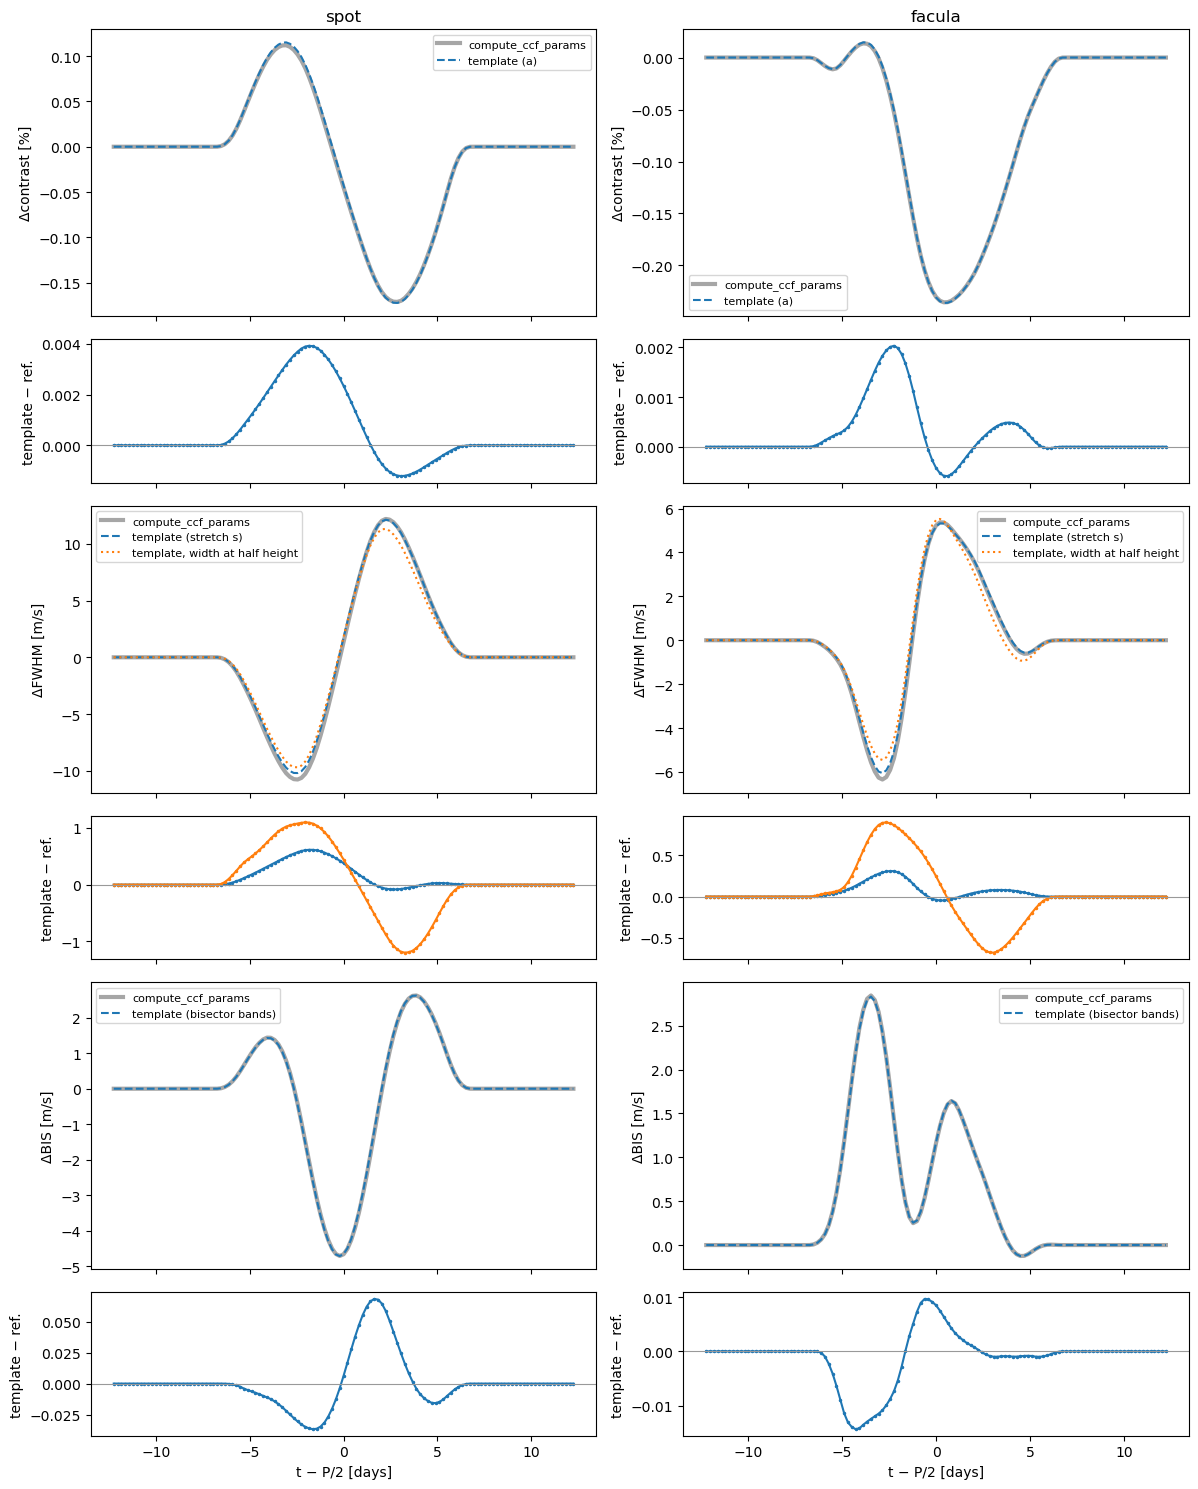

spot    contrast peak to peak 0.2830 % | contrast_template - ref: rms 0.0014, max 0.0039
spot    rv       peak to peak 11.6313 m/s | rv_template - ref: rms 0.0069, max 0.0174 | rv_bouchy - ref: rms 0.0421, max 0.0942
spot    fwhm     peak to peak 22.9790 m/s | fwhm_template - ref: rms 0.1976, max 0.6137 | fwhm_half - ref: rms 0.5517, max 1.1978
spot    bis      peak to peak 7.3440 m/s | bis_template - ref: rms 0.0213, max 0.0684
facula  contrast peak to peak 0.2491 % | contrast_template - ref: rms 0.0006, max 0.0020
facula  rv       peak to peak 7.0407 m/s | rv_template - ref: rms 0.0034, max 0.0091 | rv_bouchy - ref: rms 0.0221, max 0.0544
facula  fwhm     peak to peak 11.7194 m/s | fwhm_template - ref: rms 0.0841, max 0.3087 | fwhm_half - ref: rms 0.3570, max 0.8979
facula  bis      peak to peak 2.9692 m/s | bis_template - ref: rms 0.0048, max 0.0143


In [12]:
ind = {name: compare(sims[name].ccf_var) for name in ('spot', 'facula')}
for name in ind:
    ind[name]['contrast_gauss'] *= 100; ind[name]['contrast_template'] *= 100

rows = [('contrast', 'Δcontrast [%]', [('contrast_template', 'template (a)', 'C0--')]),
        ('fwhm', 'ΔFWHM [m/s]', [('fwhm_template', 'template (stretch s)', 'C0--'), ('fwhm_half', 'template, width at half height', 'C1:')]),
        ('bis', 'ΔBIS [m/s]', [('bis_template', 'template (bisector bands)', 'C0--')])]
fig, axes = plt.subplots(6, 2, figsize=(12, 15), sharex=True, gridspec_kw=dict(height_ratios=[2, 1] * 3))
for j, name in enumerate(('spot', 'facula')):
    r = ind[name]
    for k, (key, ylabel, curves) in enumerate(rows):
        ax, axd = axes[2 * k, j], axes[2 * k + 1, j]
        ax.plot(th, r[key + '_gauss'], 'k-', lw=3, alpha=0.35, label='compute_ccf_params')
        for col, lab, fmt in curves:
            ax.plot(th, r[col], fmt, label=lab)
            axd.plot(th, r[col] - r[key + '_gauss'], fmt[:2] + '.-', ms=3)
        axd.axhline(0, color='0.6', lw=0.8)
        ax.set_ylabel(ylabel); axd.set_ylabel('template − ref.')
        ax.legend(fontsize=8)
        if k == 0:
            ax.set_title(name)
    axes[-1, j].set_xlabel('t − P/2 [days]')
plt.tight_layout(); plt.show()

for name in ind:
    r = ind[name]
    for key, unit, cols in (('contrast', '%', ['contrast_template']), ('rv', 'm/s', ['rv_template', 'rv_bouchy']),
                            ('fwhm', 'm/s', ['fwhm_template', 'fwhm_half']), ('bis', 'm/s', ['bis_template'])):
        g = r[key + '_gauss']
        print('%-7s %-8s peak to peak %.4f %s | ' % (name, key, np.ptp(g), unit)
              + ' | '.join('%s - ref: rms %.4f, max %.4f' % (c, np.std(r[c] - g), np.max(np.abs(r[c] - g))) for c in cols))

spot    old heights   template - ref: rms 0.294 m/s, max 0.716 m/s
spot    fixed heights template - ref: rms 0.021 m/s, max 0.068 m/s
        old heights: 35 epochs with 17 heights in the bottom band instead of 16
facula  old heights   template - ref: rms 0.287 m/s, max 0.671 m/s
facula  fixed heights template - ref: rms 0.005 m/s, max 0.014 m/s
        old heights: 35 epochs with 17 heights in the bottom band instead of 16


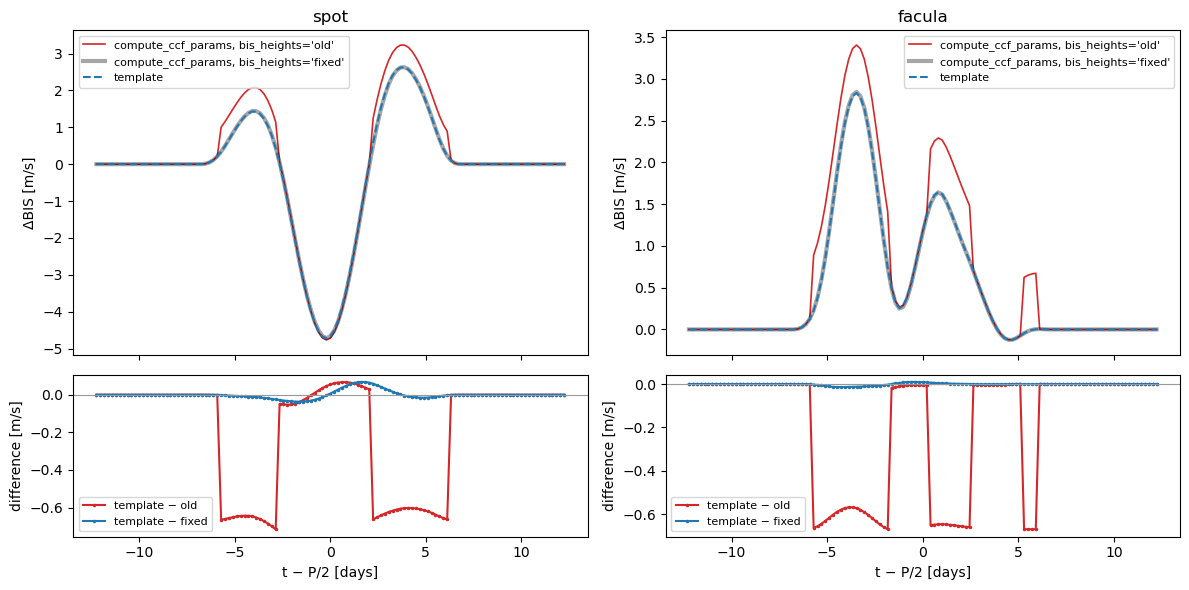

In [ ]:
# compute_ccf_params with the old heights of the bisector (bis_heights='old': the mean of its 50 heights that fall in each
# band; these heights start 10 % above the wings, so the number of them in a band changes with the CCF) and with fixed
# heights in each band (bis_heights='fixed', the default)
bis_old = {}
for name in ind:
    sims[name].bis_heights = 'old'
    *_, ybis_all = sims[name].compute_ccf_params()
    b = sims[name].compute_ccf_params()[3]
    sims[name].bis_heights = 'fixed'
    bis_old[name] = b - b[0]
    ybis_all = np.array(ybis_all)
    n_bot = ((ybis_all >= 0.1) & (ybis_all <= 0.4)).sum(1)
    for label, ref in (('old heights', bis_old[name]), ('fixed heights', ind[name]['bis_gauss'])):
        d = ind[name]['bis_template'] - ref
        print('%-7s %-13s template - ref: rms %.3f m/s, max %.3f m/s' % (name, label, np.std(d), np.max(np.abs(d))))
    print('        old heights: %d epochs with %d heights in the bottom band instead of %d'
          % ((n_bot != n_bot[0]).sum(), n_bot[n_bot != n_bot[0]][0], n_bot[0]))

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, name in enumerate(ind):
    r = ind[name]
    axes[0, j].plot(th, bis_old[name], color='C3', lw=1.2, label="compute_ccf_params, bis_heights='old'")
    axes[0, j].plot(th, r['bis_gauss'], 'k-', lw=3, alpha=0.35, label="compute_ccf_params, bis_heights='fixed'")
    axes[0, j].plot(th, r['bis_template'], 'C0--', label='template')
    axes[0, j].set_ylabel('ΔBIS [m/s]'); axes[0, j].set_title(name); axes[0, j].legend(fontsize=8)
    axes[1, j].plot(th, r['bis_template'] - bis_old[name], 'C3.-', ms=3, label='template − old')
    axes[1, j].plot(th, r['bis_template'] - r['bis_gauss'], 'C0.-', ms=3, label='template − fixed')
    axes[1, j].axhline(0, color='0.6', lw=0.8)
    axes[1, j].set_ylabel('difference [m/s]'); axes[1, j].set_xlabel('t − P/2 [days]'); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

#TODO test it on david baroch version

### Summary of section 6

Noise-free; numbers from the outputs above. `compute_ccf_params` measures the BIS at fixed heights in each band (`bis_heights='fixed'`, the default).

**Check (known deformations).** Each deformation alone is recovered to first order: a scale + offset gives Δcontrast = −2.000 % with no change in RV, FWHM or BIS; a tilted bisector of ε = 10 m/s gives ΔBIS = −4.996 m/s against −4.998 m/s for `compute_ccf_params`. The joint fit makes the RV insensitive to an offset (section 3 with the area normalisation: 0.48 m/s for an offset of 1 % of the maximum). With all the deformations ×5 (contrast −10 %, RV 50 m/s, ΔFWHM 35 m/s, ΔBIS −25 m/s) the template RV is 77.31 m/s against 77.46 m/s, once the shift terms are divided by 1 + a (without it, 10 % too small). The reference itself is not free of systematics: the gaussian fit on a fixed window gives ΔFWHM = −0.28 m/s for a pure shift of 10 m/s, and 7.14 m/s for a stretch whose true ΔFWHM is 6.98 m/s.

**Transits** (template − `compute_ccf_params`):

| | spot: peak to peak | spot: rms (max) diff. | facula: peak to peak | facula: rms (max) diff. |
|---|---|---|---|---|
| contrast | 0.28 % | 0.0014 % (0.004 %) | 0.25 % | 0.0006 % (0.002 %) |
| RV, joint fit | 11.6 m/s | 0.007 m/s (0.017) | 7.0 m/s | 0.003 m/s (0.009) |
| RV, section 3 | | 0.042 m/s (0.094) | | 0.022 m/s (0.054) |
| FWHM, stretch | 23.0 m/s | 0.20 m/s (0.61) | 11.7 m/s | 0.08 m/s (0.31) |
| FWHM, half height | | 0.55 m/s (1.20) | | 0.36 m/s (0.90) |
| BIS | 7.3 m/s | 0.021 m/s (0.068) | 3.0 m/s | 0.005 m/s (0.014) |
| BIS, `bis_heights='old'` | 8.0 m/s | 0.29 m/s (0.72) | 3.5 m/s | 0.29 m/s (0.67) |

- **Contrast and RV:** the same as the reference. The joint fit improves the RV by a factor of 6, because the offset and the scale are fitted instead of the area being normalised.
- **FWHM:** the stretch follows the gaussian FWHM to about 3 % of its peak to peak, and the difference is smooth. Part of it comes from the gaussian fit on a fixed window (see the check). The width at half height is a different quantity (it measures the flanks only) and departs more from the gaussian FWHM.
- **BIS:** the template BIS and `compute_ccf_params` agree to better than 1 % of the signal. With the old heights of the bisector (`bis_heights='old'`), `compute_ccf_params` jumps by about −0.65 m/s at the 35 epochs where its bisector has 17 heights in the bottom band instead of 16: these steps were an artefact of the old measurement, not of the template method, and they also made the old BIS peak to peak larger (8.0 against 7.3 m/s for the spot).

**Not tested here:** photon noise (weights 1/σ² in the least squares and in the band sums), and CCFs far from a gaussian.